In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import recall_score, precision_score, f1_score, log_loss
from sklearn.metrics import roc_auc_score, roc_curve

In [2]:
df = pd.read_csv("D:\\Data science\\codes\\files\\breast_cancer.csv")
df

,Unnamed: 0,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class
0,1,5,1,1,1,2,1,3,1,1,benign
1,2,5,4,4,5,7,10,3,2,1,benign
2,3,3,1,1,1,2,2,3,1,1,benign
3,4,6,8,8,1,3,4,3,7,1,benign
4,5,4,1,1,3,2,1,3,1,1,benign
...,...,...,...,...,...,...,...,...,...,...,...
678,695,3,1,1,1,3,2,1,1,1,benign
679,696,2,1,1,1,2,1,1,1,1,benign
680,697,5,10,10,3,7,3,8,10,2,malignant
681,698,4,8,6,4,3,4,10,6,1,malignant


## Data Transformation

### Standard Scalar

In [3]:
ss = StandardScaler()
SS_X = ss.fit_transform(df.iloc[:,1:10])
SS_X =pd.DataFrame(SS_X)
SS_X.columns = list(df.iloc[:,1:10])
SS_X

,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses
0,0.197905,-0.702212,-0.741774,-0.639366,-0.555608,-0.698853,-0.181827,-0.612927,-0.348400
1,0.197905,0.277252,0.262783,0.758032,1.695166,1.772867,-0.181827,-0.285105,-0.348400
2,-0.511643,-0.702212,-0.741774,-0.639366,-0.555608,-0.424217,-0.181827,-0.612927,-0.348400
3,0.552679,1.583204,1.602192,-0.639366,-0.105454,0.125054,-0.181827,1.354008,-0.348400
4,-0.156869,-0.702212,-0.741774,0.059333,-0.555608,-0.698853,-0.181827,-0.612927,-0.348400
...,...,...,...,...,...,...,...,...,...
678,-0.511643,-0.702212,-0.741774,-0.639366,-0.105454,-0.424217,-0.998853,-0.612927,-0.348400
679,-0.866417,-0.702212,-0.741774,-0.639366,-0.555608,-0.698853,-0.998853,-0.612927,-0.348400
680,0.197905,2.236180,2.271896,0.059333,1.695166,-0.149582,1.860738,2.337476,0.229166
681,-0.156869,1.583204,0.932487,0.408682,-0.105454,0.125054,2.677764,1.026185,-0.348400


### Label Encoder

In [9]:
LE = LabelEncoder()
df["LE_Class"] = LE.fit_transform(df["Class"])


In [10]:
Y = df["LE_Class"]
X = SS_X


In [ ]:
SS_X

,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses
0,0.197905,-0.702212,-0.741774,-0.639366,-0.555608,-0.698853,-0.181827,-0.612927,-0.348400
1,0.197905,0.277252,0.262783,0.758032,1.695166,1.772867,-0.181827,-0.285105,-0.348400
2,-0.511643,-0.702212,-0.741774,-0.639366,-0.555608,-0.424217,-0.181827,-0.612927,-0.348400
3,0.552679,1.583204,1.602192,-0.639366,-0.105454,0.125054,-0.181827,1.354008,-0.348400
4,-0.156869,-0.702212,-0.741774,0.059333,-0.555608,-0.698853,-0.181827,-0.612927,-0.348400
...,...,...,...,...,...,...,...,...,...
678,-0.511643,-0.702212,-0.741774,-0.639366,-0.105454,-0.424217,-0.998853,-0.612927,-0.348400
679,-0.866417,-0.702212,-0.741774,-0.639366,-0.555608,-0.698853,-0.998853,-0.612927,-0.348400
680,0.197905,2.236180,2.271896,0.059333,1.695166,-0.149582,1.860738,2.337476,0.229166
681,-0.156869,1.583204,0.932487,0.408682,-0.105454,0.125054,2.677764,1.026185,-0.348400


## Logestic Regression

logistic regresstion is applied only for binary

In [12]:
model = LogisticRegression()
model.fit(X,Y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [13]:
model.predict_proba(X) # gives actual probabilities

array([[0.98062027, 0.01937973],
       [0.09988484, 0.90011516],
       [0.98910705, 0.01089295],
       ...,
       [0.00560169, 0.99439831],
       [0.03789486, 0.96210514],
       [0.01588861, 0.98411139]])

In [14]:
np.round(model.predict_proba(X),0)

array([[1., 0.],
       [0., 1.],
       [1., 0.],
       ...,
       [0., 1.],
       [0., 1.],
       [0., 1.]])

In [15]:
df["Y_pred"] = model.predict(X)


In [16]:
df["Y_pred"]

0      0
1      1
2      0
3      1
4      0
      ..
678    0
679    0
680    1
681    1
682    1
Name: Y_pred, Length: 683, dtype: int32

In [17]:
df

,Unnamed: 0,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class,LE_Class,Y_pred
0,1,5,1,1,1,2,1,3,1,1,benign,0,0
1,2,5,4,4,5,7,10,3,2,1,benign,0,1
2,3,3,1,1,1,2,2,3,1,1,benign,0,0
3,4,6,8,8,1,3,4,3,7,1,benign,0,1
4,5,4,1,1,3,2,1,3,1,1,benign,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
678,695,3,1,1,1,3,2,1,1,1,benign,0,0
679,696,2,1,1,1,2,1,1,1,1,benign,0,0
680,697,5,10,10,3,7,3,8,10,2,malignant,1,1
681,698,4,8,6,4,3,4,10,6,1,malignant,1,1


### confusion matrix

In [18]:
cm = confusion_matrix(Y,df["Y_pred"])
cm

array([[434,  10],
       [ 10, 229]], dtype=int64)

### Accuracy score

In [19]:
score = accuracy_score(Y,df["Y_pred"])
print(f"Acuracy: {np.round(score, 2)}")

Acuracy: 0.97


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 683 entries, 0 to 682
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       683 non-null    int64 
 1   Cl.thickness     683 non-null    int64 
 2   Cell.size        683 non-null    int64 
 3   Cell.shape       683 non-null    int64 
 4   Marg.adhesion    683 non-null    int64 
 5   Epith.c.size     683 non-null    int64 
 6   Bare.nuclei      683 non-null    int64 
 7   Bl.cromatin      683 non-null    int64 
 8   Normal.nucleoli  683 non-null    int64 
 9   Mitoses          683 non-null    int64 
 10  Class            683 non-null    object
 11  LE_Class         683 non-null    int32 
 12  Y_pred           683 non-null    int32 
dtypes: int32(2), int64(10), object(1)
memory usage: 64.2+ KB


## Error Control

#### 1) sensitivity / Recoil

In [21]:
r_score = recall_score(Y, df['Y_pred'])
print(f"sensitivity = {np.round(r_score,3)}")

sensitivity = 0.958


#### 2) specificity

In [22]:
TN = cm[0,0]
FP = cm[1,0]
TNR = TN/(TN + FP)
print(f"Specificity = {np.round(TNR,3)}")

Specificity = 0.977


#### Precision

In [23]:
p_score = precision_score(Y,df["Y_pred"])
print(f"Precision = {np.round(p_score,3)}")

Precision = 0.958


#### F1 score

In [24]:
f1score = f1_score(Y,df["Y_pred"])
print(f"F1 score = {np.round(f1score,3)}")

F1 score = 0.958


### Log Loss

In [31]:
logLoss = log_loss(Y,df["Y_pred"])
print("Log Loss = ",logLoss)

Log Loss =  1.055451050925832


## Roc Curve

In [25]:
df

,Unnamed: 0,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class,LE_Class,Y_pred
0,1,5,1,1,1,2,1,3,1,1,benign,0,0
1,2,5,4,4,5,7,10,3,2,1,benign,0,1
2,3,3,1,1,1,2,2,3,1,1,benign,0,0
3,4,6,8,8,1,3,4,3,7,1,benign,0,1
4,5,4,1,1,3,2,1,3,1,1,benign,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
678,695,3,1,1,1,3,2,1,1,1,benign,0,0
679,696,2,1,1,1,2,1,1,1,1,benign,0,0
680,697,5,10,10,3,7,3,8,10,2,malignant,1,1
681,698,4,8,6,4,3,4,10,6,1,malignant,1,1


In [26]:
df["predict_prob"] = model.predict_proba(X)[:,1:]

In [27]:
TPR,FPR,dummy = roc_curve(Y, df["predict_prob"]) 

<function matplotlib.pyplot.show(close=None, block=None)>

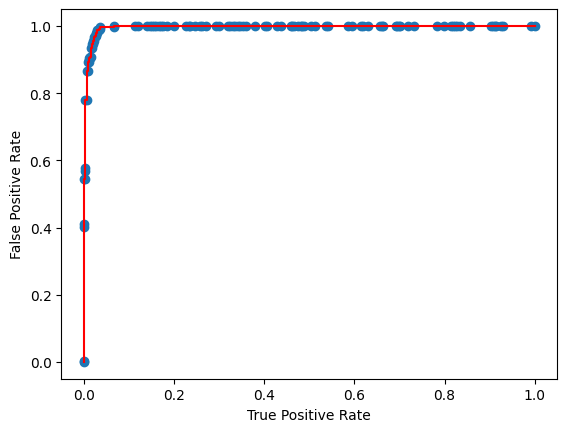

In [28]:
plt.scatter(TPR,FPR)
plt.plot(TPR,FPR, color = "Red")
plt.xlabel('True Positive Rate')
plt.ylabel('False Positive Rate')
plt.show

In [29]:
accuracy = roc_auc_score(Y,df["predict_prob"])
print("AUC-ROC:",accuracy)

AUC-ROC: 0.9962305401635945
